## Importación de módulos

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 8.7 MB/s eta 0:00:00


In [3]:
import random
import math
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import time
from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import BertForSequenceClassification, AutoTokenizer, DataCollatorWithPadding
from datasets import load_dataset
from evaluate import load
import os

## Implementación de Clase basada en polinomios de Chebishev

In [4]:
class ChebyshevPositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 512):
        super(ChebyshevPositionalEncoding, self).__init__()
        self.d_model = d_model
        self.max_len = max_len

        pe = torch.zeros(max_len, d_model)

        if max_len > 1:
            p = torch.arange(0, max_len, dtype=torch.float32)
            x = -1.0 + 2.0 * p / (max_len - 1)
        else:
            x = torch.zeros(1, dtype=torch.float32)

        arccos_x = torch.acos(x)
        k = torch.arange(0, d_model, dtype=torch.float32)

        angles = arccos_x.unsqueeze(1) * k.unsqueeze(0)

        pe = torch.cos(angles) / math.sqrt(d_model)

        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, input_ids_or_position_ids, *args, **kwargs):
        seq_len = input_ids_or_position_ids.size(1)

        return self.pe[:, :seq_len, :]

## Functions

### Function to set the seeder on each training test for the baseline and the proposed model

Changing the seed for each tuning run ensures randomness, forcing each training session to use unique values and thereby preventing anomalous results.

In [5]:
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

### Function to initialize the instance of the model, receiving a flag to switch between the baseline and the proposed model

In [6]:
def build_model(use_chebyshev: bool, device: torch.device):
    model_name = "bert-base-uncased"
    # model = DistilBertForSequenceClassification.from_pretrained(model_name, num_labels=2)
    model = BertForSequenceClassification.from_pretrained(model_name, num_labels=2)
    if use_chebyshev:
        d_model = model.config.hidden_size
        chebyshev_encoder = ChebyshevPositionalEncoding(d_model=d_model, max_len=512)
        # model.distilbert.embeddings.position_embeddings = chebyshev_encoder
        model.bert.embeddings.position_embeddings = chebyshev_encoder

    return model.to(device)

### Function to train and evaluate each model several times

In [7]:
def train_and_evaluate(model, train_loader, test_loader, device, epochs=2):
    optimizer = AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
    scaler = torch.amp.GradScaler('cuda') # Optimización de VRAM
    acc_metric = load("accuracy")
    f1_metric = load("f1")

    for epoch in range(epochs):
        epoch_start = time.time()
        model.train()
        total_loss = 0.0
        for batch in train_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            optimizer.zero_grad()

            with torch.amp.autocast('cuda'):
                outputs = model(**batch)
                loss = outputs.loss

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            total_loss += loss.item()

        epoch_duration = time.time() - epoch_start
        print(f"   Época {epoch+1}/{epochs} finalizada. Loss: {total_loss/len(train_loader):.4f} | Tiempo: {epoch_duration:.2f} segundos")

    # Evaluación en Test
    model.eval()
    with torch.no_grad():
        for batch in test_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.amp.autocast('cuda'):
                outputs = model(**batch)
            preds = torch.argmax(outputs.logits, dim=-1)
            acc_metric.add_batch(predictions=preds, references=batch["labels"])
            f1_metric.add_batch(predictions=preds, references=batch["labels"])

    return acc_metric.compute()["accuracy"], f1_metric.compute()["f1"]

## Unique loading data

The base model, the tokenizer, the dataset, and the samples are initizalized

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Ejecutando con dispositivo: {device}")
model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

raw_dataset = load_dataset("stanfordnlp/imdb")
# train_subset = raw_dataset["train"].shuffle(seed=42).select(range(5000))
# test_subset = raw_dataset["test"].shuffle(seed=42).select(range(1000))

def tokenize_fn(examples):
    return tokenizer(examples["text"], truncation=True, max_length=512)#128?

tokenized_train = raw_dataset["train"].map(tokenize_fn, batched=True).remove_columns(["text"]).rename_column("label", "labels")
tokenized_test = raw_dataset["test"].map(tokenize_fn, batched=True).remove_columns(["text"]).rename_column("label", "labels")

tokenized_train.set_format("torch")
tokenized_test.set_format("torch")

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
train_loader = DataLoader(tokenized_train, batch_size=16, shuffle=True, collate_fn=data_collator)
test_loader = DataLoader(tokenized_test, batch_size=16, collate_fn=data_collator)

save_base_dir = "./modelos_tesis"
os.makedirs(save_base_dir, exist_ok=True)
tokenizer.save_pretrained(os.path.join(save_base_dir, "tokenizer"))

Ejecutando con dispositivo: cuda


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

('./modelos_tesis/tokenizer/tokenizer_config.json',
 './modelos_tesis/tokenizer/tokenizer.json')

## Testing Execution

### Baseline Model Experiment

In [9]:
def run_baseline_experiment(seed, train_loader, test_loader, device, save_base_dir="./modelos_tesis"):
    print(f"\n[BASELINE BERT] Iniciando Semilla {seed}...")
    set_seed(seed)
    model = build_model(use_chebyshev=False, device=device)
    acc, f1 = train_and_evaluate(model, train_loader, test_loader, device)

    save_path = os.path.join(save_base_dir, f"baseline_seed_{seed}")
    model.save_pretrained(save_path)

    return {
        "model_type": "BERT-Baseline",
        "seed": seed,
        "accuracy": acc,
        "f1_score": f1,
        "model_path": save_path
    }

### Chebyshev Model Experiment

In [10]:
def run_chebyshev_experiment(seed, train_loader, test_loader, device, save_base_dir="./modelos_tesis"):
    print(f"\n[BERT-CHEBYSHEV] Iniciando Semilla {seed}...")
    set_seed(seed)
    model = build_model(use_chebyshev=True, device=device)
    acc, f1 = train_and_evaluate(model, train_loader, test_loader, device)

    save_path = os.path.join(save_base_dir, f"chebyshev_seed_{seed}")
    os.makedirs(save_path, exist_ok=True)
    torch.save(model.state_dict(), os.path.join(save_path, "model.pt"))

    return {
        "model_type": "BERT-Chebyshev",
        "seed": seed,
        "accuracy": acc,
        "f1_score": f1,
        "model_path": save_path
    }

### Execution

In [11]:
seeds = [42, 123, 999]

results = []

print("=== INICIANDO EXPERIMENTO COMPARATIVO MULTI-SEMILLA ===")

for seed in seeds:
    print(f"\n---> Corriendo experimentos para semilla {seed}...")

    res_a = run_baseline_experiment(seed, train_loader, test_loader, device)
    results.append(res_a)

    res_b = run_chebyshev_experiment(seed, train_loader, test_loader, device)
    results.append(res_b)


df_results = pd.DataFrame(results)
csv_path = "./modelos_tesis"
os.makedirs(csv_path, exist_ok=True)
df_results.to_csv(os.path.join(csv_path, "resultados_consolidados.csv"), index=False)

print("\n--- MATRIZ CONSOLIDADA DE RESULTADOS ---")
print(df_results)

summary = df_results.groupby("model_type")[["accuracy", "f1_score"]].agg(["mean", "std"])
print(summary)
print("\n\n=== EXPERIMENTO FINALIZADO ===")

=== INICIANDO EXPERIMENTO COMPARATIVO MULTI-SEMILLA ===

---> Corriendo experimentos para semilla 42...

[BASELINE BERT] Iniciando Semilla 42...


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


[BERT-CHEBYSHEV] Iniciando Semilla 999...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


   Época 1/2 finalizada. Loss: 0.3545 | Tiempo: 636.18 segundos
   Época 2/2 finalizada. Loss: 0.2471 | Tiempo: 634.24 segundos

--- MATRIZ CONSOLIDADA DE RESULTADOS ---
       model_type  seed  accuracy  f1_score  \
0   BERT-Baseline    42   0.93564  0.936845   
1  BERT-Chebyshev    42   0.88128  0.885281   
2   BERT-Baseline   123   0.94048  0.941083   
3  BERT-Chebyshev   123   0.88588  0.886565   
4   BERT-Baseline   999   0.93696  0.937066   
5  BERT-Chebyshev   999   0.88112  0.875649   

                           model_path  
0    ./modelos_tesis/baseline_seed_42  
1   ./modelos_tesis/chebyshev_seed_42  
2   ./modelos_tesis/baseline_seed_123  
3  ./modelos_tesis/chebyshev_seed_123  
4   ./modelos_tesis/baseline_seed_999  
5  ./modelos_tesis/chebyshev_seed_999  
                accuracy            f1_score          
                    mean       std      mean       std
model_type                                            
BERT-Baseline   0.937693  0.002502  0.938331  0.002386


# Results graph

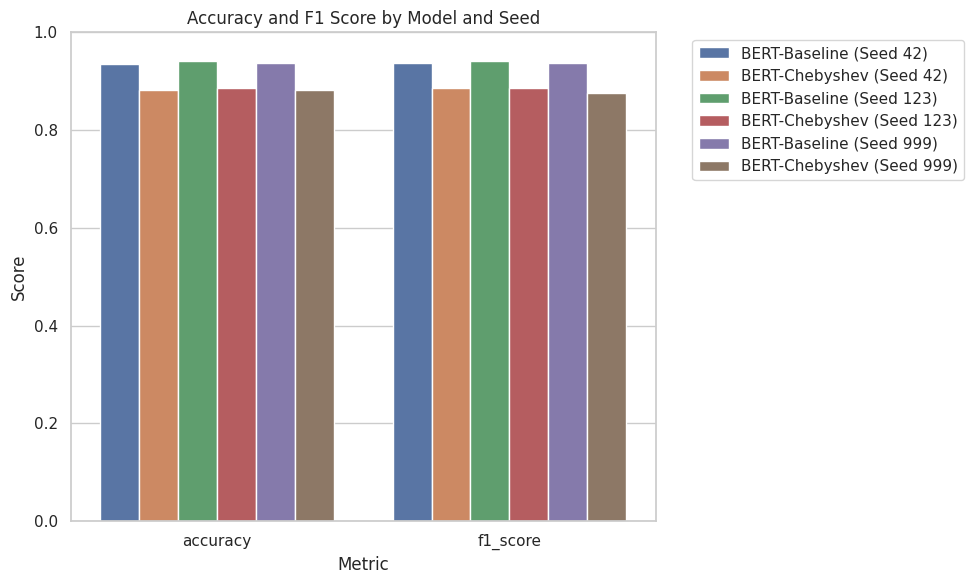

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

df_melted = df_results.melt(id_vars=['model_type', 'seed'], value_vars=['accuracy', 'f1_score'],
                            var_name='Metric', value_name='Value')
df_melted['Model-Seed'] = df_melted['model_type'] + " (Seed " + df_melted['seed'].astype(str) + ")"

ax = sns.barplot(data=df_melted, x='Metric', y='Value', hue='Model-Seed')
plt.title("Accuracy and F1 Score by Model and Seed")
plt.ylim(0.00, 1.00)
plt.ylabel("Score")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()